# Machine-learning analysis of brick compressive strength

This notebook compares Random Forest, Gradient Boosting, XGBoost and CatBoost for predicting the compressive strength of sawdust-ash bricks. It is structured for a small laboratory dataset and uses a fixed 80/20 split, Leave-One-Out Cross-Validation (LOOCV) on the training data only, conservative fixed configurations, interactive diagnostics and a manual prediction panel.

**Revision note (variant D):** this is the revised analysis. The data file is the corrected `ML_Data_CORRECTED.xlsx` (fibre 0% in the control C and the cement-only baseline M0, 0.5% in SM1–SM9). The models use the six raw physical variables only — total binder, cement share, SDA share, water content, fibre content and curing age. No engineered features are used and the mix identity and specimen number are not inputs. SHAP is computed on the trained Gradient Boosting model. Everything else follows the original notebook.



In [5]:
# Cell 1 — Install packages and import libraries
# In Google Colab, uncomment the next line if any package is missing:
!pip -q install catboost xgboost shap openpyxl plotly ipywidgets

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, LeaveOneOut
from sklearn.pipeline import Pipeline
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300})
print('Environment ready. Random state:', RANDOM_STATE)

Environment ready. Random state: 42


In [6]:
# Cell 2 — Load data, rank/remove outliers, export cleaned data, and create the 80/20 split
# Run this cell from top to bottom. Change AUTO_TOP_N to 3 for 63 rows or 5 for 61 rows.
DATA_FILE = Path('/content/ML_Data.xlsx')
if not DATA_FILE.exists():
    try:
        from google.colab import files
        files.upload()
    except Exception:
        raise FileNotFoundError('/content/ML_Data.xlsx not found. Upload it to the notebook folder and re-run this cell.')
INPUT_FILE = DATA_FILE
SHEET_NAME = 'Sawdust_Mix_Data'
TARGET = 'Compression Strength (MPa)'
ID_COL = 'Serial Number'

df = pd.read_excel(INPUT_FILE, sheet_name=SHEET_NAME)
df.columns = [str(c).strip() for c in df.columns]
for col in df.columns:
    if col not in ['Sample Type', 'Sample No.']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
if df.isna().any().any():
    raise ValueError('Missing or non-numeric values detected in the source sheet.')

# Rank deviations within each mix and curing age. This avoids calling every high-strength mix an outlier.
group_median = df.groupby(['Sample Type', 'Days'])[TARGET].transform('median')
residual = (df[TARGET] - group_median).abs()
mad = max(float(np.median(np.abs(residual - np.median(residual)))), 1e-6)
outlier_log = df[[ID_COL, 'Sample Type', 'Sample No.', 'Days', TARGET]].copy()
outlier_log['Group median (MPa)'] = group_median
outlier_log['Absolute deviation (MPa)'] = residual
outlier_log['Robust deviation score'] = 0.6745 * residual / mad
outlier_log = outlier_log.sort_values('Robust deviation score', ascending=False).reset_index(drop=True)

# Choose one method. Manual values override automatic selection.
MANUAL_OUTLIER_SERIALS = []     # Example: [12, 57, 56, 4, 10]
AUTO_SCREEN = True
AUTO_TOP_N = 2                  # Five confirmed/reviewed candidates -> 61 rows, then 48 train / 13 test.
MAX_OUTLIERS = 3

if not 0 <= AUTO_TOP_N <= MAX_OUTLIERS:
    raise ValueError('AUTO_TOP_N must be between 0 and 5.')
manual = [int(x) for x in MANUAL_OUTLIER_SERIALS]
if len(manual) > MAX_OUTLIERS or len(set(manual)) != len(manual):
    raise ValueError('Use at most five unique manual serial numbers.')
if not set(manual).issubset(set(df[ID_COL].astype(int))):
    raise ValueError('A manual serial number is not present in the source worksheet.')

if manual:
    outlier_serials = manual
    outlier_method = 'Manual laboratory-confirmed list'
elif AUTO_SCREEN:
    outlier_serials = outlier_log[ID_COL].astype(int).head(AUTO_TOP_N).tolist()
    outlier_method = f'Automatic top-{AUTO_TOP_N} robust within-group candidates; verify against lab records'
else:
    outlier_serials = []
    outlier_method = 'No outlier removal selected'

outlier_log['Removed'] = outlier_log[ID_COL].isin(outlier_serials)
outlier_log['Decision method'] = outlier_method
df_clean = df[~df[ID_COL].isin(outlier_serials)].copy().reset_index(drop=True)

# No engineered features are added in this revision. The models use the six raw
# physical variables only (see Cell 3). The water-to-binder ratio, ash-to-cement
# ratio and curing-binder interaction were tested and rejected: adding them changed
# the leave-one-out RMSE by at most 0.008 MPa for any model.

# Export the cleaned workbook before splitting.
CLEANED_FILE = Path('Brick_Cleaned_Data_D.xlsx')
cleaned_config = pd.DataFrame({
    'Item': ['Source worksheet', 'Rows before removal', 'Rows removed', 'Rows remaining', 'Removed serials', 'Outlier method'],
    'Value': [SHEET_NAME, len(df), len(outlier_serials), len(df_clean), str(outlier_serials), outlier_method]
})
with pd.ExcelWriter(CLEANED_FILE, engine='openpyxl') as writer:
    df_clean.to_excel(writer, sheet_name='Cleaned_Data', index=False)
    outlier_log.to_excel(writer, sheet_name='Outlier_Log', index=False)
    cleaned_config.to_excel(writer, sheet_name='Run_Config', index=False)

# Split only after cleaning. Stratification preserves the mix representation where possible.
try:
    train_df, test_df = train_test_split(
        df_clean, test_size=0.20, random_state=RANDOM_STATE,
        stratify=df_clean['Sample Type']
    )
    split_note = '80/20 split stratified by Sample Type'
except ValueError:
    train_df, test_df = train_test_split(df_clean, test_size=0.20, random_state=RANDOM_STATE)
    split_note = '80/20 random split; stratification unavailable'
train_df = train_df.sort_values(ID_COL).reset_index(drop=True)
test_df = test_df.sort_values(ID_COL).reset_index(drop=True)
SPLIT_FILE = Path('Brick_Train_Test_Split_D.xlsx')
with pd.ExcelWriter(SPLIT_FILE, engine='openpyxl') as writer:
    train_df.to_excel(writer, sheet_name='Train_Data', index=False)
    test_df.to_excel(writer, sheet_name='Test_Data', index=False)

print(f'Original rows: {len(df)}')
print(f'Outliers removed: {len(outlier_serials)} — {outlier_serials if outlier_serials else "None"}')
print(f'Cleaned rows: {len(df_clean)}')
print(f'Training rows: {len(train_df)} | Test rows: {len(test_df)} | Total: {len(train_df) + len(test_df)}')
print(f'Cleaned workbook: {CLEANED_FILE}')
print(f'Train/test workbook: {SPLIT_FILE}')
display(outlier_log.head(10))

Original rows: 66
Outliers removed: 2 — [12, 57]
Cleaned rows: 64
Training rows: 51 | Test rows: 13 | Total: 64
Cleaned workbook: Brick_Cleaned_Data_D.xlsx
Train/test workbook: Brick_Train_Test_Split_D.xlsx


,Serial Number,Sample Type,Sample No.,Days,Compression Strength (MPa),Group median (MPa),Absolute deviation (MPa),Robust deviation score,Removed,Decision method
0,12,M0,S3,28,3.185,1.497,1.688,17.516246,True,Automatic top-2 robust within-group candidates...
1,57,SM8,S2,7,4.042,2.717,1.325,13.749423,True,Automatic top-2 robust within-group candidates...
2,56,SM8,S1,28,3.566,2.547,1.019,10.574085,False,Automatic top-2 robust within-group candidates...
3,63,SM9,S2,7,1.836,2.818,0.982,10.190138,False,Automatic top-2 robust within-group candidates...
4,23,SM2,S3,7,2.733,2.021,0.712,7.388369,False,Automatic top-2 robust within-group candidates...
5,2,C,S1,28,1.169,0.511,0.658,6.828015,False,Automatic top-2 robust within-group candidates...
6,40,SM5,S2,28,1.636,2.199,0.563,5.842208,False,Automatic top-2 robust within-group candidates...
7,22,SM2,S2,28,2.061,1.541,0.520,5.396000,False,Automatic top-2 robust within-group candidates...
8,13,SM1,S1,7,2.436,1.923,0.513,5.323362,False,Automatic top-2 robust within-group candidates...
9,21,SM2,S2,7,1.511,2.021,0.510,5.292231,False,Automatic top-2 robust within-group candidates...


In [7]:
# Cell 3 — Prepare the feature matrix: the six raw physical variables only
# No engineered features are added, and the mix identity (Sample Type) and the
# specimen number (Sample No.) are not used as inputs. Serial Number is excluded.
MODEL_FEATURES = ['Total Binder (%)', 'Cement (% of Binder)',
                  'Ash Replacement (% of Binder)', 'Water Content (%)',
                  'Fiber (%)', 'Days']
NUMERIC_FEATURES = MODEL_FEATURES

X_train = train_df[MODEL_FEATURES].copy()
y_train = train_df[TARGET].copy()
X_test = test_df[MODEL_FEATURES].copy()
y_test = test_df[TARGET].copy()

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERIC_FEATURES)
], remainder='drop', verbose_feature_names_out=False)
models = {
    'Random Forest': Pipeline([('prep', preprocessor), ('model', RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_leaf=2, max_features=0.80,
        bootstrap=True, random_state=RANDOM_STATE, n_jobs=1
    ))]),
    'Gradient Boosting': Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.03, max_depth=2, min_samples_leaf=2,
        subsample=0.80, loss='huber', random_state=RANDOM_STATE
    ))]),
    'XGBoost': Pipeline([('prep', preprocessor), ('model', XGBRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=2, min_child_weight=3,
        subsample=0.80, colsample_bytree=0.80, reg_alpha=0.10, reg_lambda=5.0,
        objective='reg:squarederror', eval_metric='rmse', random_state=RANDOM_STATE,
        n_jobs=1, tree_method='hist'
    ))]),
    'CatBoost': CatBoostRegressor(
        iterations=300, depth=3, learning_rate=0.03, l2_leaf_reg=8.0,
        loss_function='RMSE', random_seed=RANDOM_STATE, verbose=False,
        allow_writing_files=False, thread_count=1
    )
}
loo = LeaveOneOut()
print('Features used:', MODEL_FEATURES)
print('LOOCV folds:', len(X_train))
print('Models:', list(models))



Features used: ['Total Binder (%)', 'Cement (% of Binder)', 'Ash Replacement (% of Binder)', 'Water Content (%)', 'Fiber (%)', 'Days']
LOOCV folds: 51
Models: ['Random Forest', 'Gradient Boosting', 'XGBoost', 'CatBoost']


In [8]:
# Cell 4 — Train with LOOCV, select by LOOCV RMSE, and evaluate the untouched test set
# The test set is not used for model selection.
trained_models = {}
loo_oof_predictions = {}
test_predictions = {}
cv_fold_rows = []
summary_rows = []
for model_name, base_model in models.items():
    oof = np.zeros(len(X_train), dtype=float)
    fold_errors = []
    for fold, (tr_idx, va_idx) in enumerate(loo.split(X_train), start=1):
        estimator = clone(base_model)
        estimator.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        pred = float(estimator.predict(X_train.iloc[va_idx])[0])
        actual = float(y_train.iloc[va_idx].iloc[0])
        oof[va_idx[0]] = pred
        err = actual - pred
        fold_errors.append(abs(err))
        cv_fold_rows.append({'Model': model_name, 'Fold': fold,
            'Serial Number': int(train_df.iloc[va_idx[0]][ID_COL]),
            'Actual (MPa)': actual, 'Predicted (MPa)': pred,
            'Absolute Error (MPa)': abs(err)})
    final_model = clone(base_model)
    final_model.fit(X_train, y_train)
    test_pred = final_model.predict(X_test)
    train_pred = final_model.predict(X_train)
    trained_models[model_name] = final_model
    loo_oof_predictions[model_name] = oof
    test_predictions[model_name] = np.asarray(test_pred)
    summary_rows.append({'Model': model_name,
        'Train_R2': r2_score(y_train, train_pred),
        'CV_RMSE': float(np.sqrt(np.mean((y_train.to_numpy() - oof) ** 2))),
        'CV_RMSE_SD': float(np.std(fold_errors, ddof=1)),
        'CV_MAE': float(np.mean(np.abs(y_train.to_numpy() - oof))),
        'CV_R2': r2_score(y_train, oof),
        'Test_RMSE': float(np.sqrt(mean_squared_error(y_test, test_pred))),
        'Test_MAE': float(mean_absolute_error(y_test, test_pred)),
        'Test_R2': float(r2_score(y_test, test_pred))})
cv_folds = pd.DataFrame(cv_fold_rows)
comparison = pd.DataFrame(summary_rows).sort_values('CV_RMSE').reset_index(drop=True)
BEST_MODEL = comparison.loc[0, 'Model']
print('Preferred model by lowest mean LOOCV RMSE:', BEST_MODEL)
display(comparison.style.format({c:'{:.4f}' for c in comparison.columns if c != 'Model'}))



Preferred model by lowest mean LOOCV RMSE: CatBoost


,Model,Train_R2,CV_RMSE,CV_RMSE_SD,CV_MAE,CV_R2,Test_RMSE,Test_MAE,Test_R2
0,CatBoost,0.7857,0.3974,0.2428,0.3164,0.6527,0.2620,0.2297,0.8280
1,Random Forest,0.7799,0.3994,0.2563,0.3084,0.6491,0.2634,0.2247,0.8262
2,Gradient Boosting,0.7602,0.4055,0.2550,0.3173,0.6384,0.2909,0.2464,0.7879
3,XGBoost,0.7412,0.4080,0.2491,0.3250,0.6339,0.3060,0.2553,0.7654


In [9]:
# Cell 5 — Interactive publication-quality model dashboard (Matplotlib / Seaborn version)
# Displays interactive model selection via dropdown, guaranteed to render in Colab.
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300})

model_options = list(models.keys())
model_dropdown = widgets.Dropdown(options=model_options, value=BEST_MODEL, description='Model:', style={'description_width':'initial'})
out = widgets.Output()

def render_dashboard(model_name):
    with out:
        clear_output(wait=True)
        pred_test = test_predictions[model_name]
        pred_loo = loo_oof_predictions[model_name]
        row = comparison.loc[comparison['Model'] == model_name].iloc[0]

        # 1. Summary Header
        print(f"=== {model_name} Evaluation Summary ===")
        print(f"LOOCV RMSE: {row.CV_RMSE:.3f} MPa | Test RMSE: {row.Test_RMSE:.3f} MPa | Test R²: {row.Test_R2:.3f}\n")

        # Create a multi-plot layout
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))

        # Plot A: Parity Plot
        train_plot = pd.DataFrame({'Actual': y_train, 'Predicted': pred_loo, 'Set': 'LOOCV training'})
        test_plot = pd.DataFrame({'Actual': y_test, 'Predicted': pred_test, 'Set': 'Untouched test'})
        parity = pd.concat([train_plot, test_plot], ignore_index=True)

        sns.scatterplot(data=parity, x='Actual', y='Predicted', hue='Set',
                        palette={'LOOCV training': '#2563eb', 'Untouched test': '#dc2626'},
                        alpha=0.8, ax=axes[0,0], s=80)
        lo = float(min(parity['Actual'].min(), parity['Predicted'].min()))
        hi = float(max(parity['Actual'].max(), parity['Predicted'].max()))
        axes[0,0].plot([lo, hi], [lo, hi], color='black', linestyle='--', label='Perfect prediction')
        axes[0,0].set_title(f'{model_name}: Parity Plot', fontsize=13, fontweight='bold')
        axes[0,0].set_xlabel('Actual (MPa)')
        axes[0,0].set_ylabel('Predicted (MPa)')
        axes[0,0].legend()

        # Plot B: Test-set Actual vs. Predicted bar chart
        bar_df = test_df[[ID_COL, 'Sample Type', 'Sample No.', 'Days']].copy()
        bar_df['Measured'] = y_test.to_numpy()
        bar_df['Predicted'] = pred_test
        bar_df['Label'] = bar_df.apply(lambda r: f"{r['Sample Type']}-{r['Sample No.']} ({int(r['Days'])}d)", axis=1)
        long_bar = bar_df.melt(id_vars=['Label'], value_vars=['Measured', 'Predicted'],
                               var_name='Quantity', value_name='Strength (MPa)')

        sns.barplot(data=long_bar, x='Label', y='Strength (MPa)', hue='Quantity',
                    palette={'Measured': '#1e293b', 'Predicted': '#f97316'}, ax=axes[0,1])
        axes[0,1].set_title(f'{model_name}: Unseen Test Bricks — Measured vs. Predicted', fontsize=13, fontweight='bold')
        axes[0,1].set_xlabel('')
        axes[0,1].set_ylabel('Compressive Strength (MPa)')
        axes[0,1].tick_params(axis='x', rotation=45)

        # Plot C: Test Residuals Plot
        residual_df = pd.DataFrame({'Sample Type': test_df['Sample Type'],
                                    'Predicted': pred_test,
                                    'Residual': y_test - pred_test})
        sns.scatterplot(data=residual_df, x='Predicted', y='Residual', hue='Sample Type',
                        palette='tab10', ax=axes[1,0], s=80)
        axes[1,0].axhline(y=0, color='black', linestyle='--')
        axes[1,0].set_title(f'{model_name}: Test Residuals (Actual - Predicted)', fontsize=13, fontweight='bold')
        axes[1,0].set_xlabel('Predicted (MPa)')
        axes[1,0].set_ylabel('Residual (MPa)')

        # Plot D: Absolute-error comparison boxplot (All Models)
        error_rows = []
        for m in models.keys():
            for actual, pred in zip(y_test, test_predictions[m]):
                error_rows.append({'Model': m, 'Absolute Error (MPa)': abs(actual - pred)})

        sns.boxplot(data=pd.DataFrame(error_rows), x='Model', y='Absolute Error (MPa)',
                    palette='Set2', ax=axes[1,1], width=0.5)
        sns.stripplot(data=pd.DataFrame(error_rows), x='Model', y='Absolute Error (MPa)',
                      color='black', alpha=0.6, size=5, jitter=0.15, ax=axes[1,1])
        axes[1,1].set_title('Absolute-Error Comparison on Untouched Test Set', fontsize=13, fontweight='bold')
        axes[1,1].set_xlabel('Model')
        axes[1,1].set_ylabel('Absolute Error (MPa)')

        plt.tight_layout()
        plt.savefig('Model_Evaluation_Dashboard_D.png', dpi=300, bbox_inches='tight')
        plt.show()

model_dropdown.observe(lambda change: render_dashboard(change['new']) if change['name']=='value' else None, names='value')
display(model_dropdown, out)
render_dashboard(BEST_MODEL)



Dropdown(description='Model:', index=3, options=('Random Forest', 'Gradient Boosting', 'XGBoost', 'CatBoost'),…

Output()

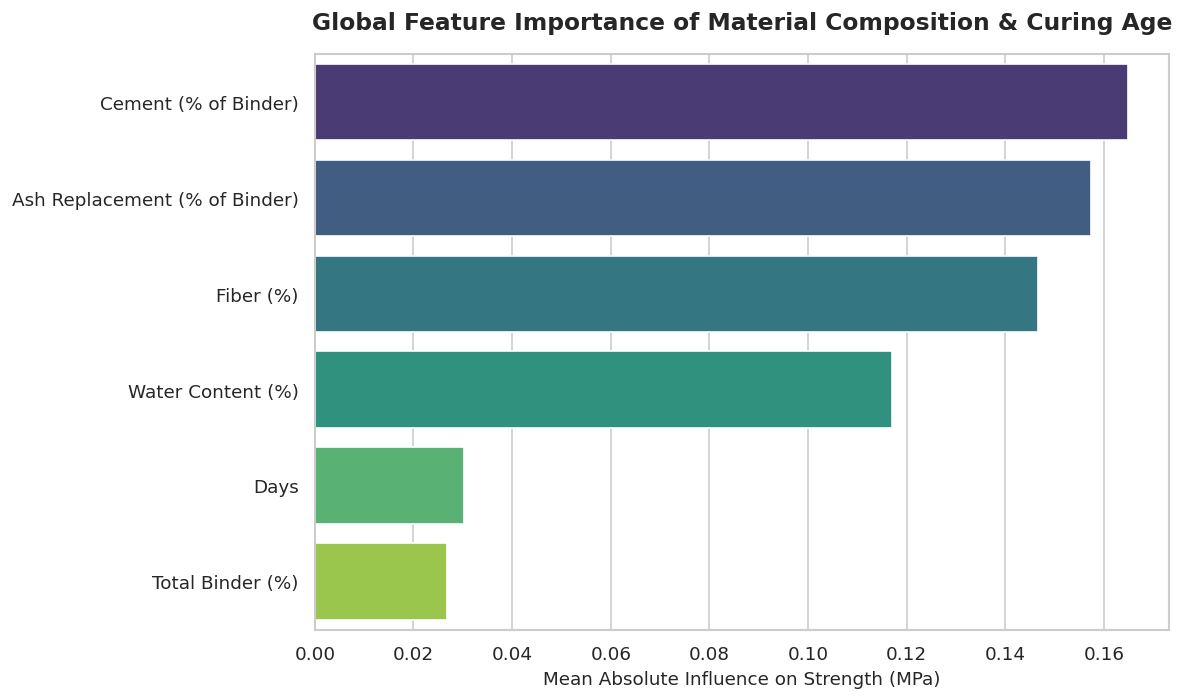

Ranked Material and Process Importances:


,Material/Process Feature,Global Importance (Mean |SHAP|)
0,Cement (% of Binder),0.1649
1,Ash Replacement (% of Binder),0.1573
2,Fiber (%),0.1467
3,Water Content (%),0.1170
4,Days,0.0303
5,Total Binder (%),0.0269


In [10]:
# Cell 6 — Global material and process feature importance
# Analyzes the overall impact of material inputs and curing time on brick compressive strength.
# Unlike the original notebook, which explained an ExtraTrees surrogate, SHAP is computed
# here on the Gradient Boosting model itself, using the same settings as Cell 3.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import shap

# Refit Gradient Boosting on the six raw inputs (same settings as the trained model)
gb_for_shap = GradientBoostingRegressor(
    n_estimators=150, learning_rate=0.03, max_depth=2, min_samples_leaf=2,
    subsample=0.80, loss='huber', random_state=RANDOM_STATE)
gb_for_shap.fit(X_train, y_train)

# Compute global SHAP values over the six raw inputs
explainer = shap.TreeExplainer(gb_for_shap)
shap_values = explainer.shap_values(X_train)

# Calculate mean absolute SHAP values to represent global feature importance
importance_df = pd.DataFrame({
    'Material/Process Feature': MODEL_FEATURES,
    'Global Importance (Mean |SHAP|)': np.abs(shap_values).mean(axis=0)
}).sort_values('Global Importance (Mean |SHAP|)', ascending=False).reset_index(drop=True)

# Render global importance plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x='Global Importance (Mean |SHAP|)',
    y='Material/Process Feature',
    palette='viridis',
    hue='Material/Process Feature',
    legend=False
)
plt.title('Global Feature Importance of Material Composition & Curing Age', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mean Absolute Influence on Strength (MPa)', fontsize=11)
plt.ylabel('')
plt.tight_layout()
plt.savefig('Global_Material_Importance_D.png', dpi=300, bbox_inches='tight')
plt.show()

print("Ranked Material and Process Importances:")
display(importance_df.style.format({'Global Importance (Mean |SHAP|)': '{:.4f}'}))



In [11]:
# Cell 7 — Interactive manual prediction for a user-created mix
# Use the sliders and dropdown menus to customize a mixture composition and curing age.
# Only the six raw inputs are offered: the mix identity and specimen number are not
# inputs to the models, and no engineered features are used.
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import numpy as np

# Numeric sliders matching the domain constraints
binder_slider = widgets.FloatSlider(value=6.0, min=0.0, max=15.0, step=0.5, description='Binder (%):')
cement_slider = widgets.FloatSlider(value=95.0, min=0.0, max=100.0, step=1.0, description='Cement (%):')
ash_slider = widgets.FloatSlider(value=5.0, min=0.0, max=100.0, step=1.0, description='Ash (%):')
water_slider = widgets.FloatSlider(value=10.0, min=0.0, max=25.0, step=0.5, description='Water (%):')
fiber_slider = widgets.FloatSlider(value=0.5, min=0.0, max=3.0, step=0.1, description='Fiber (%):')
days_slider = widgets.IntSlider(value=28, min=1, max=365, step=1, description='Curing Age (Days):')

output_box = widgets.Output()

def update_predictions(*args):
    with output_box:
        clear_output(wait=True)

        # 1. Structure the raw interactive values into a DataFrame row
        manual_raw = pd.DataFrame([{
            'Total Binder (%)': binder_slider.value,
            'Cement (% of Binder)': cement_slider.value,
            'Ash Replacement (% of Binder)': ash_slider.value,
            'Water Content (%)': water_slider.value,
            'Fiber (%)': fiber_slider.value,
            'Days': days_slider.value
        }])
        manual_input = manual_raw[MODEL_FEATURES]

        # 2. Predict across all evaluated models
        try:
            manual_results = []
            for model_name, fitted in trained_models.items():
                pred = fitted.predict(manual_input)[0]
                manual_results.append({
                    'Model': model_name,
                    'Predicted Compressive Strength (MPa)': float(pred)
                })

            manual_results = pd.DataFrame(manual_results).sort_values(
                'Predicted Compressive Strength (MPa)', ascending=False
            )

            print("--- Formulated Parameters ---")
            display(manual_input)
            print("\n--- Model Performance Predictions ---")
            display(manual_results.style.format({'Predicted Compressive Strength (MPa)':'{:.4f}'}))

        except Exception as e:
            print("Evaluation error: ", e)

# Observe and trigger updates on any user adjustment
all_widgets = [
    binder_slider, cement_slider, ash_slider,
    water_slider, fiber_slider, days_slider
]
for widget in all_widgets:
    widget.observe(update_predictions, names='value')

# Arrange and display parameters layout
left_column = widgets.VBox([binder_slider, cement_slider, ash_slider])
right_column = widgets.VBox([water_slider, fiber_slider, days_slider])
ui = widgets.HBox([left_column, right_column])

display(ui, output_box)
update_predictions()



Output()

In [12]:
# Cell 8 — Export publication results to a multi-tab Excel workbook
OUTPUT_FILE = Path('Brick_Compressive_Strength_Publication_Results_D.xlsx')

run_config = pd.DataFrame({
    'Item': ['Source worksheet', 'Rows before outlier removal', 'Rows removed', 'Rows modeled', 'Train rows', 'Test rows', 'Split', 'CV method', 'Random state', 'Selected model'],
    'Value': [SHEET_NAME, len(df), len(outlier_serials), len(df_clean), len(train_df), len(test_df), split_note, 'Leave-One-Out (LOOCV)', RANDOM_STATE, BEST_MODEL]
})
test_export = test_df[[ID_COL, 'Sample Type', 'Sample No.', 'Days', TARGET]].copy()
for model_name in model_options:
    test_export[f'{model_name} Prediction (MPa)'] = test_predictions[model_name]
test_export['Selected Model Residual (MPa)'] = test_export[TARGET] - test_export[f'{BEST_MODEL} Prediction (MPa)']

# Safely extract the current settings from the interactive panel to save to the workbook
try:
    manual_raw = pd.DataFrame([{
        'Total Binder (%)': binder_slider.value,
        'Cement (% of Binder)': cement_slider.value,
        'Ash Replacement (% of Binder)': ash_slider.value,
        'Water Content (%)': water_slider.value,
        'Fiber (%)': fiber_slider.value,
        'Days': days_slider.value
    }])
    manual_input = manual_raw[MODEL_FEATURES]
    current_manual_results = []
    for model_name, fitted in trained_models.items():
        pred = fitted.predict(manual_input)[0]
        current_manual_results.append({
            'Model': model_name,
            'Predicted Compressive Strength (MPa)': float(pred)
        })
    manual_export_df = pd.DataFrame(current_manual_results).sort_values(
        'Predicted Compressive Strength (MPa)', ascending=False
    )
except Exception:
    # Fallback to empty DataFrame if widgets are not initialized
    manual_export_df = pd.DataFrame(columns=['Model', 'Predicted Compressive Strength (MPa)'])

with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Original_Data', index=False)
    df_clean.to_excel(writer, sheet_name='Cleaned_Data', index=False)
    outlier_log.to_excel(writer, sheet_name='Outlier_Log', index=False)
    train_df.to_excel(writer, sheet_name='Train_Data', index=False)
    test_df.to_excel(writer, sheet_name='Test_Data', index=False)
    cv_folds.to_excel(writer, sheet_name='LOOCV_Fold_Results', index=False)
    comparison.to_excel(writer, sheet_name='Model_Comparison', index=False)
    test_export.to_excel(writer, sheet_name='Test_Predictions', index=False)
    manual_export_df.to_excel(writer, sheet_name='Manual_Prediction', index=False)
    importance_df.to_excel(writer, sheet_name='Material_Importance', index=False)
    run_config.to_excel(writer, sheet_name='Run_Config', index=False)

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
wb = load_workbook(OUTPUT_FILE)
for ws in wb.worksheets:
    ws.freeze_panes = 'A2'
    ws.auto_filter.ref = ws.dimensions
    ws.sheet_view.showGridLines = False
    for cell in ws[1]:
        cell.font = Font(bold=True, color='FFFFFF')
        cell.fill = PatternFill('solid', fgColor='1F4E78')
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    for col in ws.columns:
        letter = col[0].column_letter
        width = min(max(max(len(str(c.value)) if c.value is not None else 0 for c in col[:100]) + 2, 12), 32)
        ws.column_dimensions[letter].width = width
wb.save(OUTPUT_FILE)
print('Saved:', OUTPUT_FILE)
try:
    from google.colab import files
    files.download(str(OUTPUT_FILE))
except Exception:
    pass



Saved: Brick_Compressive_Strength_Publication_Results_D.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>